Week 3 notebook, forward and backward selection, principal component regression, and partial least squares, Mike Hembree

Same MIMIC-IV demo feature table as the other weeks, 140 ICU stays, length of stay in days as the continuous target, ten predictors. The idea this week is that a lot of the predictors are doing similar jobs (two blood pressures, GCS and delirium moving together), so I want to see whether picking a smaller set of variables or building a few combined components predicts better than using everything.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split, RepeatedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, roc_auc_score, roc_curve, f1_score, recall_score, precision_score, accuracy_score, confusion_matrix

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'serif'


In [2]:
# load the feature table and fill the few missing values with the median
feat = pd.read_csv('delirium_features.csv')

rcols = ['anchor_age', 'gender', 'heart_rate', 'sbp', 'dbp', 'resp_rate', 'temp_f', 'spo2', 'gcs_total_min', 'delirium_positive']
ccols = rcols[:-1]

data = feat[rcols + ['los']].copy()
for c in rcols:
    data[c] = data[c].fillna(data[c].median())

X = data[rcols]
y = data['los']
Xc = data[ccols]
yc = feat['delirium_positive'].fillna(0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size = 0.2, random_state = 42, stratify = yc)

cv_reg = RepeatedKFold(n_splits = 5, n_repeats = 6, random_state = 1)
cv_clf = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 3, random_state = 1)
print(data.shape, yc.value_counts().to_dict())


(140, 11) {0: 95, 1: 45}


In [3]:
# models, all scaling happens inside the pipeline so cross validation stays honest
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression

def cv_rmse(model):
    r = cross_validate(model, X, y, cv = cv_reg, scoring = ('r2', 'neg_root_mean_squared_error'), n_jobs = 2)
    return -r['test_neg_root_mean_squared_error'].mean(), r['test_r2'].mean()

rows = []
for k in range(1, 11):
    for d in ['forward', 'backward']:
        if k == 10 and d == 'backward':
            continue
        sel = SequentialFeatureSelector(LinearRegression(), n_features_to_select = k if k < 10 else 'auto', direction = d, cv = 5) if k < 10 else None
        m = make_pipeline(StandardScaler(), sel, LinearRegression()) if sel is not None else make_pipeline(StandardScaler(), LinearRegression())
        a, b = cv_rmse(m)
        rows.append({'method': d + ' selection' if k < 10 else 'all ten predictors', 'k': k, 'cv rmse': a, 'cv r2': b})
    a, b = cv_rmse(make_pipeline(StandardScaler(), PCA(k), LinearRegression()))
    rows.append({'method': 'pcr', 'k': k, 'cv rmse': a, 'cv r2': b})
    a, b = cv_rmse(make_pipeline(StandardScaler(), PLSRegression(k)))
    rows.append({'method': 'plsr', 'k': k, 'cv rmse': a, 'cv r2': b})
res3 = pd.DataFrame(rows)
res3.to_csv('figs/wk3_results.csv', index = False)
res3.pivot_table(index = 'k', columns = 'method', values = 'cv rmse').round(3)


method,all ten predictors,backward selection,forward selection,pcr,plsr
k,,,,,
1,NaN,3.262,3.262,3.617,3.215
2,NaN,3.268,3.282,3.214,3.293
3,NaN,3.286,3.292,3.248,3.333
4,NaN,3.300,3.314,3.247,3.339
5,NaN,3.322,3.327,3.214,3.350
6,NaN,3.330,3.331,3.233,3.350
7,NaN,3.347,3.340,3.265,3.350
8,NaN,3.328,3.335,3.291,3.350
9,NaN,3.324,3.330,3.305,3.350


In [4]:
# best setting for each method
best = res3.loc[res3.groupby('method')['cv rmse'].idxmin()].sort_values('cv rmse')
best


,method,k,cv rmse,cv r2
18,pcr,5,3.213644,0.241009
3,plsr,1,3.215096,0.234781
0,forward selection,1,3.262005,0.226475
1,backward selection,1,3.262005,0.226475
36,all ten predictors,10,3.350120,0.151098


Every selection or reduction method beat using all ten predictors under cross validation (rmse 3.35). PCR with 5 components and PLSR with 1 component are basically tied for best at about 3.21, and forward and backward selection both ended up at 1 variable with an rmse of 3.26.

In [5]:
# which variables forward and backward selection pick on the full data
for d in ['forward', 'backward']:
    for k in [2, 3, 4]:
        s = make_pipeline(StandardScaler(), SequentialFeatureSelector(LinearRegression(), n_features_to_select = k, direction = d, cv = 5)).fit(X, y)
        print(d, k, list(X.columns[s[-1].get_support()]))


forward 2 ['heart_rate', 'delirium_positive']
forward 3 ['heart_rate', 'dbp', 'delirium_positive']


forward 4 ['heart_rate', 'dbp', 'spo2', 'delirium_positive']


backward 2 ['heart_rate', 'delirium_positive']


backward 3 ['heart_rate', 'dbp', 'delirium_positive']


backward 4 ['heart_rate', 'dbp', 'spo2', 'delirium_positive']


Forward and backward selection agree with each other every time, which is a nice sanity check. With one variable they both pick delirium_positive, with two they add heart_rate, with three dbp, and with four spo2. It's a little surprising that gcs_total_min doesn't get picked early, but it makes sense since gcs and the delirium flag are correlated at negative 0.38, so once delirium is in the model gcs adds less than heart rate does.

In [6]:
# pca structure, explained variance and loadings on the first two components
pca = PCA().fit(StandardScaler().fit_transform(X))
print(np.round(pca.explained_variance_ratio_, 3))
print(np.round(np.cumsum(pca.explained_variance_ratio_), 3))
load = pd.DataFrame(pca.components_[:2].T, index = rcols, columns = ['pc1', 'pc2']).round(2)
load


[0.195 0.161 0.138 0.114 0.111 0.087 0.062 0.061 0.04  0.032]
[0.195 0.356 0.494 0.608 0.719 0.805 0.867 0.928 0.968 1.   ]


,pc1,pc2
anchor_age,-0.13,0.28
gender,-0.01,-0.11
heart_rate,-0.28,-0.20
sbp,0.53,-0.03
dbp,0.54,-0.20
resp_rate,-0.41,0.11
temp_f,-0.08,-0.27
spo2,0.22,-0.47
gcs_total_min,0.28,0.53
delirium_positive,-0.17,-0.49


The first two principal components only explain about 36 percent of the variance together and it takes five to get to 72 percent, so there isn't one obvious low dimensional story. PC1 is mostly the two blood pressures (loadings around 0.53 and 0.54), PC2 leans on gcs_total_min against delirium_positive and spo2.

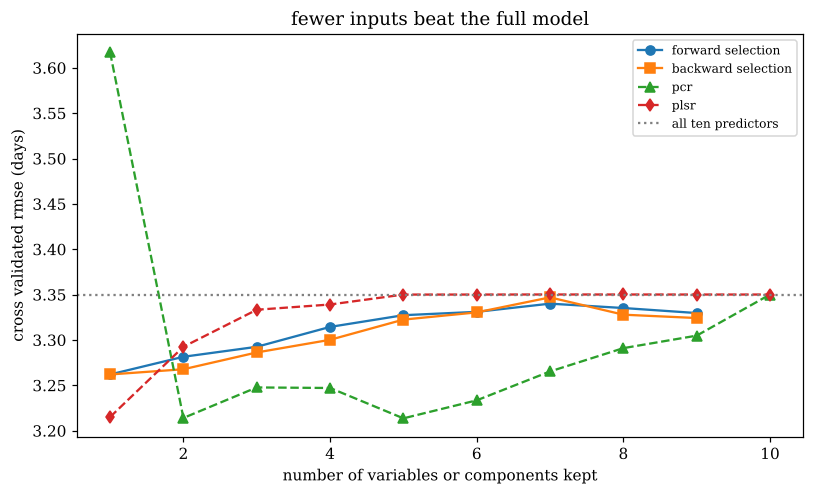

In [7]:
# figure, cv rmse against number of variables or components
fig, ax = plt.subplots(figsize = (7.5, 4.6))
for name, style in [('forward selection', 'o-'), ('backward selection', 's-'), ('pcr', '^--'), ('plsr', 'd--')]:
    s = res3[res3.method == name]
    ax.plot(s['k'], s['cv rmse'], style, label = name)
full = res3[res3.method == 'all ten predictors']['cv rmse'].iloc[0]
ax.axhline(full, color = 'gray', linestyle = ':', label = 'all ten predictors')
ax.set_xlabel('number of variables or components kept')
ax.set_ylabel('cross validated rmse (days)')
ax.set_title('fewer inputs beat the full model')
ax.legend(fontsize = 8)
plt.tight_layout()
plt.savefig('figs/selection.png', dpi = 200)
plt.show()


In [8]:
# holdout check with the same split used in weeks 2 and 4
def hold(name, model):
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    p = np.ravel(p)
    return {'model': name, 'test r2': r2_score(y_test, p), 'test rmse': mean_squared_error(y_test, p) ** 0.5}

kf = int(best[best.method == 'forward selection']['k'].iloc[0])
kb = int(best[best.method == 'backward selection']['k'].iloc[0])
kp = int(best[best.method == 'pcr']['k'].iloc[0])
kl = int(best[best.method == 'plsr']['k'].iloc[0])
print(kf, kb, kp, kl)
pd.DataFrame([
    hold('all ten', make_pipeline(StandardScaler(), LinearRegression())),
    hold('forward', make_pipeline(StandardScaler(), SequentialFeatureSelector(LinearRegression(), n_features_to_select = kf, direction = 'forward', cv = 5), LinearRegression())),
    hold('backward', make_pipeline(StandardScaler(), SequentialFeatureSelector(LinearRegression(), n_features_to_select = kb, direction = 'backward', cv = 5), LinearRegression())),
    hold('pcr', make_pipeline(StandardScaler(), PCA(kp), LinearRegression())),
    hold('plsr', make_pipeline(StandardScaler(), PLSRegression(kl))),
])


1 1 5 1


,model,test r2,test rmse
0,all ten,0.338080,3.131483
1,forward,0.384581,3.019484
2,backward,0.384581,3.019484
3,pcr,0.309272,3.198901
4,plsr,0.302485,3.214579


On the holdout split forward and backward selection with one variable got a test r squared of 0.385, better than the all predictor linear model at 0.338, while PCR and PLSR landed a bit lower at 0.31 and 0.30. I wouldn't read much into the ordering with 28 test stays, the repeated cv table is the better evidence, and it says all four methods are about equally good and all better than using everything.